# 05 · K-Means v02: cuántos grupos y con qué entradas

**Objetivo:** justificar con datos (y con sus límites) las dos decisiones del perfil: **cuántos grupos** (K) y **qué índices entran**. Aquí solo se explora; el perfil final se genera en el notebook 07 y los experimentos se registran en MLflow en el 06.

**Orden:** después del 04 (que guarda la tabla de variables). **Guarda** `experimentos_v02.csv` y `modelo_elegido_v02.json`, que leen el 06 y el 07.

**Cómo leer las métricas:**
- *Silhouette* (más alto = grupos más separados) y *Davies-Bouldin* (más bajo = mejor).
- *Estabilidad* (ARI entre semillas; 1 = siempre los mismos grupos).
- *Grupo menor* (% de municipios del grupo más pequeño).
- **Solo se pueden comparar métricas de la misma matriz de entrada.** Entre entradas distintas el silhouette no es comparable (son espacios distintos).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(ROOT / 'src'))  # por si no se ha hecho pip install -e .

from sitewise.ml.experimentos import barrido_k, estabilidad, matriz_entrada
from sitewise.ml.indices import INDICES, construir_indices

DATASET = ROOT / 'data/processed/sitewise_v04_candidata/dataset_municipal.csv'
COMPONENTES = ROOT / 'data/processed/sitewise_dimensiones_v01/componentes_percentiles.csv'
K_ELEGIDO = 4
ML = ROOT / 'data/processed/sitewise_ml'
ML.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200)

# Comprobación de orden: el 04 debe haberse ejecutado y sus variables de perfil deben ser las que usa el código.
if not (ML / 'variables_perfil_v02.csv').exists():
    raise FileNotFoundError('Falta variables_perfil_v02.csv: ejecuta antes el notebook 04.')
d = pd.read_csv(DATASET, dtype={'cod_ine': str})
componentes = pd.read_csv(COMPONENTES)
d = d.join(construir_indices(d, componentes))

# Índice natural (JRC), solo para la prueba de la sección 3: media de sus 2 percentiles, sin imputar.
comp = componentes.assign(_k=componentes['cod_ine'].astype(int)).set_index('_k')
alineado = comp.reindex(d['cod_ine'].astype(int).to_numpy())
alineado.index = d.index
d['idx_natural'] = alineado[[c for c in comp.columns if c.startswith('dimension_natural_jrc__')]].mean(axis=1, skipna=False)

CONFIGURACIONES = {
    'logística + hídrica': ['idx_logistica', 'idx_hidrica'],
    'logística + conectividad': ['idx_logistica', 'idx_conectividad'],
    'logística + hídrica + conectividad (elegida)': INDICES,
    '+ natural JRC': INDICES + ['idx_natural'],
}
X, con_perfil = matriz_entrada(d, INDICES)
vars_04 = pd.read_csv(ML / 'variables_perfil_v02.csv')
vars_04 = set(vars_04.loc[vars_04['uso'].str.startswith('Perfil'), 'variable'])
vars_codigo = {c.split('__', 1)[1] for c in componentes.columns
               if c.startswith(('dimension_logistica__', 'dimension_hidrica__', 'alternativa_conectividad__'))}
assert vars_04 == vars_codigo, f'El 04 y el código no coinciden: {vars_04 ^ vars_codigo}'
print(f'Municipios con los tres índices: {len(X)} de {len(d)} ({len(X)/len(d):.1%})')

Municipios con los tres índices: 7971 de 8132 (98.0%)


## 1. ¿Cuántos grupos? Barrido de K de 2 a 8 con los tres índices

       inercia  silhouette  davies_bouldin  calinski_harabasz  grupo_menor_pct  ari_medio  ari_minimo
k                                                                                                    
2  7094551.337       0.308           1.291           4215.214           44.900      0.998       0.994
3  5550827.938       0.299           1.182           3801.403           24.288      0.998       0.998
4  4434412.828       0.285           1.127           3840.496           19.910      0.996       0.995
5  3845105.997       0.275           1.055           3626.647           17.137      0.991       0.985
6  3361541.137       0.269           1.058           3547.419           12.621      0.979       0.970
7  3065251.927       0.260           1.093           3369.805           11.203      0.973       0.935
8  2827964.829       0.255           1.109           3225.842            8.920      0.967       0.947


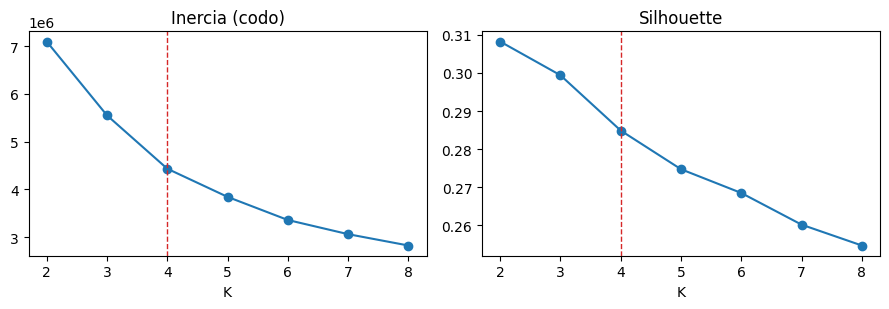

In [2]:
tabla = barrido_k(X, ks=range(2, 9))
est = {k: estabilidad(X, k) for k in tabla.index}
tabla['ari_medio'] = [est[k]['ari_medio'] for k in tabla.index]
tabla['ari_minimo'] = [est[k]['ari_minimo'] for k in tabla.index]
print(tabla.round(3).to_string())

fig, ejes = plt.subplots(1, 2, figsize=(9, 3.2))
ejes[0].plot(tabla.index, tabla['inercia'], marker='o'); ejes[0].set_title('Inercia (codo)')
ejes[1].plot(tabla.index, tabla['silhouette'], marker='o'); ejes[1].set_title('Silhouette')
for a in ejes:
    a.axvline(K_ELEGIDO, color='tab:red', ls='--', lw=1); a.set_xlabel('K')
plt.tight_layout(); plt.show()

**Qué dicen los datos (y qué no).**

- El silhouette es **más alto con K=2** y va bajando al subir K; no hay un "codo" claro en la inercia. Los índices son percentiles casi uniformes: K-Means **corta un continuo** y ningún K destaca por tener grupos claramente separados.
- Hasta K=4 los grupos son muy estables entre semillas (ARI mínimo ≥ 0,99) y con K=5 siguen siéndolo (≥ 0,98); a partir de K=6 la estabilidad empieza a bajar y el grupo menor queda por debajo del 13 % de los municipios.
- Por tanto **los datos no eligen K=4 por sí solos**. K=4 es una **decisión de interpretación**: con 4 grupos cada perfil se describe en una frase (buena logística; presión hídrica alta; aislado y mal conectado; poca logística pero bien conectado), que es lo que pidió el revisor técnico (poder explicar cada grupo). Con K=2 solo habría "bueno" y "malo"; con K=6 o más, grupos que cuesta nombrar.
- Es una opción defendible, no la única; si el equipo prefiere K=3, solo cambia la constante `K` del notebook 07.

## 2. ¿Qué índices entran? Alternativas de entrada

Se prueban K=3 y K=4 con cuatro conjuntos de entradas. El silhouette de cada fila **no se compara con el de otra** (otro espacio). Lo que sí se compara es la **cobertura**: cuántos municipios quedan con perfil.

In [3]:
filas = []
for nombre, columnas in CONFIGURACIONES.items():
    Xc, mascara = matriz_entrada(d, columnas)
    t = barrido_k(Xc, ks=[3, 4], n_init=10)
    for k in (3, 4):
        filas.append({'configuracion': nombre, 'variables': ', '.join(columnas), 'filas': len(Xc), 'k': k, 'n_init': 10,
                      'cobertura_pct': round(mascara.mean() * 100, 1), **t.loc[k].to_dict()})
alternativas = pd.DataFrame(filas)
print(alternativas[['configuracion', 'filas', 'cobertura_pct', 'k', 'silhouette', 'grupo_menor_pct']].round(3).to_string(index=False))

                               configuracion  filas  cobertura_pct  k  silhouette  grupo_menor_pct
                         logística + hídrica   7971           98.0  3       0.402           23.510
                         logística + hídrica   7971           98.0  4       0.366           17.375
                    logística + conectividad   7971           98.0  3       0.381           32.342
                    logística + conectividad   7971           98.0  4       0.372           22.243
logística + hídrica + conectividad (elegida)   7971           98.0  3       0.299           24.288
logística + hídrica + conectividad (elegida)   7971           98.0  4       0.285           19.859
                               + natural JRC   4025           49.5  3       0.253           24.720
                               + natural JRC   4025           49.5  4       0.223           20.994


**Lectura.**

- **Añadir el índice natural (JRC)** deja el perfil con la mitad de los municipios (≈ 49,5 %), porque inundaciones e incendios solo tienen dato en parte del territorio y no se imputan. Se descarta para el perfil; los riesgos naturales quedan como **datos sueltos** (y la API puede mostrar los cercanos).
- **Quitar la conectividad** (solo logística + hídrica) da el silhouette más alto, pero **no es comparable** y se pierde una dimensión que el equipo quiere ver: la conectividad separa a los municipios aislados de los que no lo están.
- **Quitar la hídrica** dejaría el perfil sin el único factor de presión sobre el agua, que es lo que distingue al grupo 1.
- La elegida (**logística + hídrica + conectividad**) mantiene el 98 % de municipios y tres entradas, por debajo del máximo de 3–4 del revisor técnico (es un techo, no un mínimo).

> Lo no resuelto: estas comparaciones usan silhouette sobre percentiles casi uniformes, que es una guía débil. La justificación principal sigue siendo la interpretación empresarial de cada grupo (ver notebook 07).

## 3. Guardar los resultados

Se guardan para el siguiente notebook: `experimentos_v02.csv` (todas las pruebas, que el 06 registra en MLflow) y `modelo_elegido_v02.json` (K y entradas, que lee el 07).

In [4]:
import hashlib, json

sha = hashlib.sha256(DATASET.read_bytes()).hexdigest()[:12]
barrido = tabla.reset_index().assign(tipo='barrido_k', configuracion='logistica_hidrica_conectividad',
                                       variables=', '.join(INDICES), filas=len(X), n_init=20, cobertura_pct=round(len(X) / len(d) * 100, 1))
alt = alternativas.assign(tipo='alternativa_entrada', configuracion=alternativas['configuracion'].map(
    {'logística + hídrica': 'logistica_hidrica', 'logística + conectividad': 'logistica_conectividad',
     'logística + hídrica + conectividad (elegida)': 'logistica_hidrica_conectividad', '+ natural JRC': 'logistica_hidrica_conectividad_natural'}))
experimentos = pd.concat([barrido, alt], ignore_index=True).assign(semilla=42, sha256_dataset=sha)
experimentos.to_csv(ML / 'experimentos_v02.csv', index=False, encoding='utf-8', lineterminator='\n')

modelo = {'version_modelo': 'v02', 'k': K_ELEGIDO, 'entradas': INDICES, 'semilla': 42, 'n_init': 20,
          'motivo': 'Elegido por interpretación y cobertura, no por una métrica (ver notebook 05).'}
(ML / 'modelo_elegido_v02.json').write_text(json.dumps(modelo, ensure_ascii=False, indent=2), encoding='utf-8')
print(len(experimentos), 'pruebas guardadas en', (ML / 'experimentos_v02.csv').relative_to(ROOT))
print('Modelo elegido:', modelo)

15 pruebas guardadas en data\processed\sitewise_ml\experimentos_v02.csv
Modelo elegido: {'version_modelo': 'v02', 'k': 4, 'entradas': ['idx_logistica', 'idx_hidrica', 'idx_conectividad'], 'semilla': 42, 'n_init': 20, 'motivo': 'Elegido por interpretación y cobertura, no por una métrica (ver notebook 05).'}


## 4. Conclusiones

- **K=4** con **logística + hídrica + conectividad**, decididos por interpretación y cobertura, no porque una métrica lo señale.
- Grupos **estables** entre semillas (ARI ≥ 0,99).
- Siguiente paso: el notebook 06 registra estos experimentos en MLflow (los lee de `experimentos_v02.csv`) y el 07 genera el perfil final con el K guardado en `modelo_elegido_v02.json`.